# RF 추가 실험 3·4·5 — 공통 110개 특징

**RF 담당자용 Google Colab 노트북**입니다. LR·SVM은 학습하지 않습니다.

- 실험 3: 트리 수·깊이·분기 특징 수·최소 리프 표본 수를 **5개 후보**로 점검합니다.
- 실험 4: Closed-world / Open-world 다중 / Open-world 이진의 RF 기준 결과를 만듭니다.
- 실험 5: 이진 검증 확률로 FPR 목표별 임계값을 고르고, 고정한 임계값을 저장합니다.
- 실험 6 준비: RF의 OOF·test 전체 클래스 확률과 ID·클래스 순서를 내보냅니다. **앙상블 실험 자체는 수행하지 않습니다.**

공통 기준은 **trim0, 기존 110개 특징(g6 50지점), 기존 split_seed42.csv, 5-fold**입니다.
중복·상수 열도 임의로 제거하지 않으며 RF에는 표준화를 적용하지 않습니다.
Open-world 결과에는 초반 패킷 방향 등 데이터 수집 방식 차이의 영향이 섞일 수 있습니다.
특정 특징을 임의로 제외하거나 별도 확인 플래그를 설정하지 않습니다.

**실행 순서:** 0번 경로 확인 → 위에서 아래로 실행. 학습 중단 후에는 같은 설정으로 다시 실행하면 완료한 fold를 재사용합니다.
CV로 모델 설정과 임계값을 고정한 뒤 최종 test 지표를 계산합니다. test 결과를 보고 후보·임계값을 다시 선택하지 마세요.
test 평가는 잠시 미루고 싶다면 0번의 `EVALUATE_FINAL_TEST=False`로 바꿀 수 있습니다.


## 0. 경로와 실행 설정

필요한 파일: `features_mon_trim0.csv`, `features_unmon10k_trim0.csv`, 기존 `split_seed42.csv`.
이전 코드의 `*_trim0_cumul50.csv` 파일명도 허용합니다. **100지점 CSV는 사용하지 않습니다.**

목표 FPR 1%·5%·10%는 **비교용 제안값**입니다. 팀에서 정한 값이 있으면 `FPR_TARGETS`를 바꾸세요.
FPR은 실제 Unmonitored를 Monitored로 잘못 예측한 비율입니다.


In [1]:
FEATURE_DIR = "/content/drive/MyDrive/MLB-Project/feature"
RESULT_ROOT = "/content/drive/MyDrive/MLB-Project/results"
SPLIT_PATH = RESULT_ROOT + "/split_seed42.csv"
RESULT_DIR = RESULT_ROOT + "/rf_experiments3_4_5_110features"

SEED = 42
N_FOLDS = 5
N_JOBS = -1  # RF 안에서만 CPU 병렬 처리; fold·후보는 차례로 실행
TASKS = ["closed_world", "open_multi", "open_binary"]
EXPECTED_MON_CLASSES = 95
USE_CACHE = True
HEARTBEAT_SECONDS = 300
FPR_TARGETS = [0.01, 0.05, 0.10]  # 팀 합의 전 비교용 후보
EXPORT_TEST_PROBABILITIES = True  # test 정답을 이용하지 않고 확률만 저장
EVALUATE_FINAL_TEST = True        # CV로 설정·임계값을 먼저 고정한 뒤 마지막에 평가

# 이전 RF 그룹 단독 실험의 고정값을 기준으로, 한 항목씩 바꿉니다.
# depth_none은 sklearn 기본 RF와 같은 주요 설정도 확인하는 후보입니다.
BASE_PARAMS = dict(n_estimators=100, max_depth=20,
                   max_features="sqrt", min_samples_leaf=1)
CANDIDATES = [
    dict(name="baseline", **BASE_PARAMS),
    dict(name="depth_none", **{**BASE_PARAMS, "max_depth": None}),
    dict(name="trees_500", **{**BASE_PARAMS, "n_estimators": 500}),
    dict(name="features_half", **{**BASE_PARAMS, "max_features": 0.5}),
    dict(name="leaf_3", **{**BASE_PARAMS, "min_samples_leaf": 3}),
]


## 1. 라이브러리와 저장 함수

Colab은 **CPU 런타임**이면 됩니다. 이 코드의 sklearn RF는 GPU를 사용하지 않습니다.
한 후보의 fold가 끝날 때마다 저장하고 후보 완료 시 한 줄만 출력합니다. 오래 걸리면 5분마다 진행 fold 수를 알려줍니다.


In [2]:
import os, json, time, tempfile, platform, threading
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from joblib import hash as joblib_hash
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount("/content/drive")

def atomic_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", dir=path.parent,
                                     suffix=".tmp", delete=False) as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, allow_nan=False)
        temp = f.name
    os.replace(temp, path)

def atomic_csv(frame, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8-sig", dir=path.parent,
                                     suffix=".tmp", delete=False, newline="") as f:
        frame.to_csv(f, index=False); temp = f.name
    os.replace(temp, path)

def atomic_npz(path, **arrays):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="wb", dir=path.parent, suffix=".tmp", delete=False) as f:
        np.savez_compressed(f, **arrays); temp = f.name
    os.replace(temp, path)

VERSIONS = dict(python=platform.python_version(), sklearn=sklearn.__version__,
                numpy=np.__version__, pandas=pd.__version__)
print("실행 버전:", VERSIONS)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
실행 버전: {'python': '3.13.18', 'sklearn': '1.6.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}


## 2. 110개 특징·공유 분할 확인

메타데이터 6개는 학습 입력에서 제외합니다. 특징은 g1=3, g2=17, g3=6, g4=3, g5=31, g6=50개로 검증합니다.
기존 공유 분할 파일이 없으면 멈춥니다. LR·SVM과 다른 분할을 실수로 만드는 것을 막기 위해 자동 생성하지 않습니다.

**다른 모델 담당자와 확인:** CSV 버전, 특징 열·순서, train/test ID, 아래 `cv_assignment.csv`가 같아야 합니다.
단순히 seed만 같아도 입력 행 순서가 다르면 CV fold는 달라질 수 있습니다.


In [3]:
INFO_COLS = ["record_id", "dataset", "page_id", "sample_idx", "label", "trim"]
GROUP_SIZES = {"g1":3, "g2":17, "g3":6, "g4":3, "g5":31, "g6":50}

def load_features(kind):
    paths = [Path(FEATURE_DIR)/f"features_{kind}_trim0_cumul50.csv",
             Path(FEATURE_DIR)/f"features_{kind}_trim0.csv"]
    path = next((p for p in paths if p.is_file()), None)
    if path is None:
        raise FileNotFoundError("FEATURE_DIR를 확인하세요: " + ", ".join(map(str, paths)))
    df = pd.read_csv(path, dtype={"record_id":str})
    if df.columns[:6].tolist() != INFO_COLS or not df.columns.is_unique:
        raise ValueError("메타데이터 6개 또는 중복 열 이름을 확인하세요.")
    cols = [c for c in df if any(c.startswith(g+"_") for g in GROUP_SIZES)]
    counts = {g:sum(c.startswith(g+"_") for c in cols) for g in GROUP_SIZES}
    if counts != GROUP_SIZES or set(df) != set(INFO_COLS+cols):
        raise ValueError(f"110개 특징/50지점 CSV가 필요합니다. 그룹별 개수: {counts}")
    if df.record_id.isna().any() or df.record_id.duplicated().any():
        raise ValueError("record_id가 누락되었거나 중복입니다.")
    if not df.dataset.eq(kind).all() or not df.trim.eq(0).all():
        raise ValueError("dataset 또는 trim0 조건 불일치")
    if not np.isfinite(df[cols].to_numpy(dtype=float)).all():
        raise ValueError("특징에 NaN/inf가 있습니다.")
    y = df.label.to_numpy(dtype=float)
    if not np.isfinite(y).all() or not np.equal(y, np.floor(y)).all():
        raise ValueError("정수 라벨이 필요합니다.")
    df["label"] = y.astype(int)
    if kind == "mon":
        if sorted(df.label.unique()) != list(range(EXPECTED_MON_CLASSES)):
            raise ValueError("mon 라벨 0~94를 확인하세요.")
    elif not df.label.eq(-1).all():
        raise ValueError("unmon 라벨은 -1이어야 합니다.")
    return df, cols, path

mon, FEATS, MON_PATH = load_features("mon")
unmon, ufeats, UNMON_PATH = load_features("unmon10k")
if FEATS != ufeats or set(mon.record_id) & set(unmon.record_id):
    raise ValueError("mon/unmon 특징 순서 불일치 또는 ID 중복")
split = pd.read_csv(SPLIT_PATH, dtype={"record_id":str})
if not {"record_id", "split"}.issubset(split):
    raise ValueError("분할 CSV에 record_id, split 열이 필요합니다.")
if (split.record_id.isna().any() or split.record_id.duplicated().any()
        or not split.split.isin(["train", "test"]).all()):
    raise ValueError("분할 ID 중복/누락 또는 train/test 표기 오류")
all_ids = set(mon.record_id) | set(unmon.record_id)
if not all_ids.issubset(set(split.record_id)):
    raise ValueError("공유 분할에 없는 CSV의 ID가 있습니다.")
lookup = split.set_index("record_id")["split"]
mon = mon.assign(split=mon.record_id.map(lookup))
unmon = unmon.assign(split=unmon.record_id.map(lookup))
for df in [mon, unmon]:
    if set(df.split) != {"train", "test"}:
        raise ValueError("각 데이터에 train/test가 모두 필요합니다.")

def make_task(task):
    if task not in {"closed_world", "open_multi", "open_binary"}:
        raise ValueError(f"알 수 없는 과제: {task}")
    df = mon.copy() if task == "closed_world" else pd.concat([mon, unmon], ignore_index=True)
    df["y"] = np.where(df.dataset.eq("mon"),1,-1) if task == "open_binary" else df.label
    tr = df.loc[df.split.eq("train")].reset_index(drop=True)
    te = df.loc[df.split.eq("test")].reset_index(drop=True)
    if set(tr.y) != set(te.y) or tr.y.value_counts().min() < N_FOLDS:
        raise ValueError("클래스 누락 또는 fold별 표본 부족")
    folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(tr[FEATS], tr.y))
    fid = np.full(len(tr), -1, dtype=int)
    for k, (_, iv) in enumerate(folds, 1): fid[iv] = k
    return dict(train=tr, test=te, folds=folds, fold_id=fid,
                classes=np.sort(tr.y.unique()).astype(int))

TASK_DATA = {t:make_task(t) for t in TASKS}
assert len(CANDIDATES) == len({c["name"] for c in CANDIDATES})
combined = pd.concat([mon, unmon], ignore_index=True)
display(pd.crosstab(combined.dataset, combined.split))
display(pd.DataFrame(CANDIDATES))
print(f"총 {len(TASKS)*len(CANDIDATES)*N_FOLDS}회 CV fit + 선택 모델 {len(TASKS)}회 최종 fit(확률 저장 시)")
print("한 후보씩 점검하는 소규모 비교입니다. 모든 조합의 최적값을 찾는 그리드 서치는 아닙니다.")


split,test,train
dataset,,
mon,3800,15200
unmon10k,2000,8000


,name,n_estimators,max_depth,max_features,min_samples_leaf
0,baseline,100,20.0,sqrt,1
1,depth_none,100,NaN,sqrt,1
2,trees_500,500,20.0,sqrt,1
3,features_half,100,20.0,0.5,1
4,leaf_3,100,20.0,sqrt,3


총 75회 CV fit + 선택 모델 3회 최종 fit(확률 저장 시)
한 후보씩 점검하는 소규모 비교입니다. 모든 조합의 최적값을 찾는 그리드 서치는 아닙니다.


## 3. 평가·캐시·확률 저장 준비

CV(교차검증)는 train을 5개로 나누어 4개로 학습하고 남은 1개로 검증하는 과정을 반복합니다.
OOF 예측은 **그 기록을 학습에 쓰지 않은 fold 모델이 만든 검증 예측**입니다.
각 후보에서 이를 저장하므로 실험 4·5를 위해 5-fold 학습을 다시 할 필요가 없습니다.

선택 기준은 기존 실험과 동일한 **평균 CV 정확도 최대**입니다. 정확히 동률이면 위 후보 순서를 따릅니다.
Macro-F1, Open-world 탐지 지표, 학습 정확도와 시간도 함께 기록합니다.
다중 분류 `mon_site_exact`의 분모는 **실제 Monitored 전체**이며, -1로 놓친 경우도 오답입니다.


In [4]:
SCHEMA = "rf345_110_v1"

def model_for(candidate):
    params = {k:v for k,v in candidate.items() if k != "name"}
    return RandomForestClassifier(**params, random_state=SEED, n_jobs=N_JOBS,
        criterion="gini", min_samples_split=2, bootstrap=True, class_weight=None)

def score_metrics(y, pred, task, proba=None, classes=None):
    y, pred = np.asarray(y), np.asarray(pred)
    out = dict(acc=float(accuracy_score(y,pred)),
               macro_f1=float(f1_score(y,pred,average="macro",zero_division=0)))
    if task != "closed_world":
        yt, yp = np.where(y>=0,1,-1), np.where(pred>=0,1,-1)
        tn,fp,fn,tp = confusion_matrix(yt,yp,labels=[-1,1]).ravel()
        div = lambda a,b: float(a/b) if b else 0.0
        out.update(TP=int(tp),FN=int(fn),TN=int(tn),FP=int(fp),
                   tpr=div(tp,tp+fn),tnr=div(tn,tn+fp),fpr=div(fp,fp+tn),
                   precision=div(tp,tp+fp))
        if task == "open_multi":
            out["mon_site_exact"] = float(np.mean(y[y>=0] == pred[y>=0]))
        elif proba is not None:
            p = proba[:,list(classes).index(1)]
            out["roc_auc"] = float(roc_auc_score(y,p))
            out["average_precision"] = float(average_precision_score(y,p,pos_label=1))
    return out

def aligned_proba(model, X, classes):
    if set(model.classes_) != set(classes):
        raise ValueError("학습 fold에 없는 클래스가 있습니다.")
    p = model.predict_proba(X)[:,[list(model.classes_).index(c) for c in classes]]
    if not np.isfinite(p).all() or not np.allclose(p.sum(axis=1),1):
        raise ValueError("예측 확률 오류")
    return p

DATA_HASH = joblib_hash((mon[INFO_COLS+FEATS+["split"]],unmon[INFO_COLS+FEATS+["split"]]))
RUN_ID = joblib_hash((SCHEMA,DATA_HASH,FEATS,CANDIDATES,SEED,N_FOLDS,VERSIONS))
RUN_DIR = Path(RESULT_DIR)/"runs"/RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
atomic_csv(split.loc[split.record_id.isin(all_ids)], RUN_DIR/"split_used.csv")
atomic_json(RUN_DIR/"protocol.json", dict(schema=SCHEMA,run_id=RUN_ID,data_hash=DATA_HASH,
    features=FEATS,n_features=110,cumul_points=50,trim=0,seed=SEED,n_folds=N_FOLDS,
    candidates=CANDIDATES,versions=VERSIONS,selection="mean_cv_acc; exact ties: candidate order",
    preprocessing="none",probability_calibration="none",fpr_targets=FPR_TARGETS,
    sources=[str(MON_PATH),str(UNMON_PATH)],shared_split=str(SPLIT_PATH),
    interpretation="Open-world may include collection artifacts; no feature exclusions"))
for task,d in TASK_DATA.items():
    folder = RUN_DIR/task; folder.mkdir(parents=True, exist_ok=True)
    atomic_csv(d["train"][["record_id","y"]].assign(cv_fold=d["fold_id"]), folder/"cv_assignment.csv")
    atomic_json(folder/"probability_columns.json", dict(classes=d["classes"].tolist(),
        probability_columns=[f"p_{c}" for c in d["classes"]],features=FEATS,
        calibration="none",alignment="join on record_id; reorder probability columns by classes"))

def export_predictions(folder, prefix, frame, classes, pred, proba, fold_id=None, include_y=True):
    table = frame[["record_id"]].copy()
    if include_y: table["y_true"] = frame.y.to_numpy()
    if fold_id is not None: table["cv_fold"] = fold_id
    table["pred"] = pred
    table = pd.concat([table,pd.DataFrame(proba,columns=[f"p_{c}" for c in classes])],axis=1)
    atomic_csv(table, folder/f"{prefix}_predictions.csv")
    arrays = dict(record_id=frame.record_id.to_numpy(dtype=str),classes=classes,pred=pred,proba=proba)
    if include_y: arrays["y_true"] = frame.y.to_numpy()
    if fold_id is not None: arrays["cv_fold"] = fold_id
    atomic_npz(folder/f"{prefix}_probabilities.npz",**arrays)

CV_RESULTS, SELECTED, OOF = {}, {}, {}
print("결과 폴더:", RUN_DIR)


결과 폴더: /content/drive/MyDrive/MLB-Project/results/rf_experiments3_4_5_110features/runs/29c10470afbc6158f597ca2749dac781


## 4. 실험 3 — RF 설정 적정성 점검

기준 `100 / 20 / sqrt / 1`에서 한 항목만 바꿔 원인을 비교합니다.

| 후보 | 기준과 다른 항목 | 확인할 내용 |
|---|---|---|
| baseline | 없음 | 이전 고정 RF 기준 |
| depth_none | 깊이 20 → 제한 없음 | 깊이 제한이 학습을 방해했는지 |
| trees_500 | 트리 100 → 500 | 트리 증가의 이득과 시간 비용 |
| features_half | 분기 특징 sqrt → 0.5 | 분기마다 더 많은 특징을 보는 효과 |
| leaf_3 | 최소 리프 1 → 3 | 작은 리프를 줄이는 규제의 효과 |

`None`도 데이터와 분할 종료 조건 때문에 유한한 트리가 됩니다.
110개 입력에서 `sqrt`는 분기 후보 특징 10개, `0.5`는 55개입니다.
기준보다 좋은 변경을 모두 합친 조합까지 검증한 것은 아닙니다. 필요하면 후속 후보 하나를 별도 추가하세요.
**깊이만 비교하면 깊이의 영향만 알 수 있으므로, 이번에는 네 항목을 모두 소수 후보로 확인합니다.**


In [5]:
def evaluate_candidate(task, candidate):
    d = TASK_DATA[task]; tr = d["train"]; classes = d["classes"]
    X, y = tr[FEATS], tr.y.to_numpy()
    sig = joblib_hash((SCHEMA,task,tr[["record_id","y"]+FEATS],d["folds"],
                       model_for(candidate).get_params(),VERSIONS))
    folder = RUN_DIR/task/candidate["name"]/sig[:16]
    folder.mkdir(parents=True, exist_ok=True)
    pred = np.empty(len(tr),dtype=int)
    proba = np.full((len(tr),len(classes)),np.nan)
    rows = []; state = {"done":0}; stop = threading.Event()
    start = time.perf_counter()
    def report():
        while not stop.wait(HEARTBEAT_SECONDS):
            print(f"[진행] {task}/{candidate['name']} {state['done']}/{N_FOLDS} fold 완료 | "
                  f"경과 {(time.perf_counter()-start)/60:.1f}분",flush=True)
    thread = threading.Thread(target=report,daemon=True); thread.start()
    try:
        for k,(it,iv) in enumerate(d["folds"],1):
            path = folder/f"fold_{k}.npz"
            reused = bool(USE_CACHE and path.is_file())
            if reused:
                with np.load(path,allow_pickle=False) as z:
                    if (z["signature"].item()!=sig or not np.array_equal(z["validation_index"],iv)
                            or not np.array_equal(z["classes"],classes)):
                        raise ValueError("저장 fold의 서명/인덱스/클래스 불일치")
                    pv, pp = z["pred"].copy(), z["proba"].copy()
                    fit_s, predict_s, train_acc = map(float,[z["fit_s"],z["predict_s"],z["train_acc"]])
                if pp.shape != (len(iv),len(classes)) or not np.isfinite(pp).all():
                    raise ValueError("저장 fold 확률 오류")
            else:
                model = model_for(candidate)
                t = time.perf_counter(); model.fit(X.iloc[it],y[it]); fit_s = time.perf_counter()-t
                t = time.perf_counter()
                pp = aligned_proba(model,X.iloc[iv],classes)
                # sklearn RF predict와 같은 규칙: 최대 확률, 동률이면 classes 순서
                pv = classes[np.argmax(pp,axis=1)]
                train_acc = float(accuracy_score(y[it],model.predict(X.iloc[it])))
                predict_s = time.perf_counter()-t
                if USE_CACHE:
                    atomic_npz(path,signature=np.array(sig),validation_index=iv,classes=classes,
                        pred=pv,proba=pp,fit_s=np.array(fit_s),predict_s=np.array(predict_s),
                        train_acc=np.array(train_acc))
                del model
            pred[iv], proba[iv] = pv, pp
            rows.append(dict(fold=k,train_acc=train_acc,fit_s=fit_s,predict_s=predict_s,
                reused=reused,**score_metrics(y[iv],pv,task,pp,classes)))
            state["done"] = k
        folds = pd.DataFrame(rows)
        atomic_csv(folds,folder/"cv_folds.csv")
        row = dict(task=task,candidate=candidate["name"],n_features=len(FEATS),
            cv_acc=float(folds.acc.mean()),cv_std=float(folds.acc.std(ddof=0)),
            cv_macro_f1=float(folds.macro_f1.mean()),train_acc=float(folds.train_acc.mean()),
            cv_fit_s=float(folds.fit_s.sum()),cv_predict_s=float(folds.predict_s.sum()),
            reused_folds=int(folds.reused.sum()),result_folder=str(folder),signature=sig,
            **{k:v for k,v in candidate.items() if k!="name"})
        row["train_cv_gap"] = row["train_acc"]-row["cv_acc"]
        for metric in ["mon_site_exact","tpr","tnr","fpr","precision","roc_auc","average_precision"]:
            if metric in folds: row["cv_"+metric] = float(folds[metric].mean())
        atomic_json(folder/"cv_summary.json",row)
        print(f"[완료] {task}/{candidate['name']}: CV {row['cv_acc']:.4f} ± {row['cv_std']:.4f} | "
              f"기록된 학습 {row['cv_fit_s']/60:.1f}분 | 재사용 {row['reused_folds']}/{N_FOLDS}",flush=True)
        return row,dict(pred=pred,proba=proba,folds=folds,classes=classes,signature=sig)
    finally:
        stop.set(); thread.join(timeout=1)

def run_task(task):
    rows, outputs = [], {}
    print(f"[시작] {task}: {len(CANDIDATES)}후보 × {N_FOLDS}fold",flush=True)
    for candidate in CANDIDATES:
        row,out = evaluate_candidate(task,candidate)
        rows.append(row); outputs[candidate["name"]] = out
        atomic_csv(pd.DataFrame(rows),RUN_DIR/task/"experiment3_candidates.csv")
    table = pd.DataFrame(rows)
    table["delta_cv_vs_baseline"] = table.cv_acc-table.iloc[0].cv_acc
    winner = int(np.argmax(table.cv_acc.to_numpy()))
    chosen = CANDIDATES[winner].copy()
    table["selected"] = table.candidate.eq(chosen["name"])
    CV_RESULTS[task], SELECTED[task], OOF[task] = table, chosen, outputs[chosen["name"]]
    # 같은 fold끼리 차이를 비교합니다. fold 표준편차만으로 유의성을 단정하지 않습니다.
    base = outputs[CANDIDATES[0]["name"]]["folds"].acc.to_numpy()
    paired = pd.DataFrame([{ "candidate":c["name"],"fold":k+1,
        "delta_acc_vs_baseline":float(v-base[k])}
        for c in CANDIDATES for k,v in enumerate(outputs[c["name"]]["folds"].acc)])
    atomic_csv(paired,RUN_DIR/task/"experiment3_paired_fold_deltas.csv")
    atomic_csv(table,RUN_DIR/task/"experiment3_candidates.csv")
    atomic_json(RUN_DIR/task/"selected_params.json",dict(candidate=chosen,
        model_params=model_for(chosen).get_params(),selection="mean_cv_acc; exact ties: candidate order",
        signature=OOF[task]["signature"],classes=TASK_DATA[task]["classes"].tolist()))
    display(table[[c for c in ["candidate","cv_acc","cv_std","delta_cv_vs_baseline", "cv_macro_f1",
        "train_cv_gap","cv_mon_site_exact","cv_tpr","cv_fpr","cv_fit_s","selected"] if c in table]].round(4))
    print(f"[선택] {task}: {chosen['name']} (test 사용 없음)",flush=True)


### 4-1. Closed-world — 주요 실험

Monitored 95개 사이트를 서로 구분합니다. 끝나면 후보 비교표가 표시됩니다.


In [6]:
if "closed_world" in TASKS: run_task("closed_world")


[시작] closed_world: 5후보 × 5fold
[완료] closed_world/baseline: CV 0.8476 ± 0.0068 | 기록된 학습 2.0분 | 재사용 5/5
[완료] closed_world/depth_none: CV 0.8518 ± 0.0051 | 기록된 학습 1.9분 | 재사용 5/5
[완료] closed_world/trees_500: CV 0.8547 ± 0.0069 | 기록된 학습 9.4분 | 재사용 5/5
[완료] closed_world/features_half: CV 0.8411 ± 0.0068 | 기록된 학습 10.4분 | 재사용 5/5
[완료] closed_world/leaf_3: CV 0.8322 ± 0.0079 | 기록된 학습 1.7분 | 재사용 5/5


,candidate,cv_acc,cv_std,delta_cv_vs_baseline,cv_macro_f1,train_cv_gap,cv_fit_s,selected
0,baseline,0.8476,0.0068,0.0000,0.8464,0.1524,122.6226,False
1,depth_none,0.8518,0.0051,0.0042,0.8505,0.1482,116.8537,False
2,trees_500,0.8547,0.0069,0.0071,0.8536,0.1453,563.8472,True
3,features_half,0.8411,0.0068,-0.0065,0.8396,0.1576,623.3975,False
4,leaf_3,0.8322,0.0079,-0.0155,0.8304,0.1592,102.6730,False


[선택] closed_world: trees_500 (test 사용 없음)


### 4-2. Open-world 다중 — 주요 실험

95개 사이트 + Unmonitored(-1), 총 96개 클래스를 구분합니다.
전체 정확도와 실제 Monitored의 사이트 번호 정답률을 함께 봅니다.


In [7]:
if "open_multi" in TASKS: run_task("open_multi")


[시작] open_multi: 5후보 × 5fold
[완료] open_multi/baseline: CV 0.8019 ± 0.0060 | 기록된 학습 3.0분 | 재사용 5/5
[완료] open_multi/depth_none: CV 0.8147 ± 0.0039 | 기록된 학습 3.2분 | 재사용 4/5
[진행] open_multi/trees_500 1/5 fold 완료 | 경과 5.0분
[진행] open_multi/trees_500 3/5 fold 완료 | 경과 10.0분
[진행] open_multi/trees_500 4/5 fold 완료 | 경과 15.0분
[완료] open_multi/trees_500: CV 0.8056 ± 0.0059 | 기록된 학습 15.3분 | 재사용 0/5
[진행] open_multi/features_half 1/5 fold 완료 | 경과 5.0분
[진행] open_multi/features_half 3/5 fold 완료 | 경과 10.0분
[진행] open_multi/features_half 4/5 fold 완료 | 경과 15.0분
[완료] open_multi/features_half: CV 0.8095 ± 0.0075 | 기록된 학습 16.3분 | 재사용 0/5
[완료] open_multi/leaf_3: CV 0.7779 ± 0.0065 | 기록된 학습 2.9분 | 재사용 0/5


,candidate,cv_acc,cv_std,delta_cv_vs_baseline,cv_macro_f1,train_cv_gap,cv_mon_site_exact,cv_tpr,cv_fpr,cv_fit_s,selected
0,baseline,0.8019,0.0060,0.0000,0.7892,0.1954,0.7073,0.7580,0.0185,182.5910,False
1,depth_none,0.8147,0.0039,0.0128,0.8025,0.1853,0.7276,0.7820,0.0198,192.1354,True
2,trees_500,0.8056,0.0059,0.0037,0.7949,0.1925,0.7109,0.7561,0.0146,918.4424,False
3,features_half,0.8095,0.0075,0.0076,0.7888,0.1847,0.7280,0.8088,0.0356,977.9993,False
4,leaf_3,0.7779,0.0065,-0.0240,0.7601,0.1795,0.6691,0.7186,0.0154,174.9448,False


[선택] open_multi: depth_none (test 사용 없음)


### 4-3. Open-world 이진 — 보조 실험 및 임계값 분석용

Monitored(1)인지 Unmonitored(-1)인지만 구분합니다. 사이트 번호는 맞히지 않습니다.
실험 5를 위해 이 과제도 필요합니다.


In [8]:
if "open_binary" in TASKS: run_task("open_binary")


[시작] open_binary: 5후보 × 5fold
[완료] open_binary/baseline: CV 0.8889 ± 0.0041 | 기록된 학습 1.7분 | 재사용 0/5
[완료] open_binary/depth_none: CV 0.8941 ± 0.0043 | 기록된 학습 1.8분 | 재사용 0/5
[진행] open_binary/trees_500 2/5 fold 완료 | 경과 5.0분
[완료] open_binary/trees_500: CV 0.8908 ± 0.0044 | 기록된 학습 8.5분 | 재사용 0/5
[진행] open_binary/features_half 2/5 fold 완료 | 경과 5.0분
[완료] open_binary/features_half: CV 0.8926 ± 0.0043 | 기록된 학습 8.9분 | 재사용 0/5
[완료] open_binary/leaf_3: CV 0.8855 ± 0.0047 | 기록된 학습 1.6분 | 재사용 0/5


,candidate,cv_acc,cv_std,delta_cv_vs_baseline,cv_macro_f1,train_cv_gap,cv_tpr,cv_fpr,cv_fit_s,selected
0,baseline,0.8889,0.0041,0.0000,0.8712,0.1083,0.9611,0.2482,101.4466,False
1,depth_none,0.8941,0.0043,0.0052,0.8783,0.1059,0.9578,0.2269,106.5834,True
2,trees_500,0.8908,0.0044,0.0019,0.8734,0.1067,0.9627,0.2458,510.1206,False
3,features_half,0.8926,0.0043,0.0037,0.8768,0.1028,0.9539,0.2239,536.6539,False
4,leaf_3,0.8855,0.0047,-0.0034,0.8670,0.1032,0.9601,0.2561,98.2112,False


[선택] open_binary: depth_none (test 사용 없음)


## 5. 실험 4 — RF 공통 조건 결과·OOF 확률 내보내기

선택한 후보의 기존 OOF 예측을 재사용합니다. 이 셀은 **추가 fit가 없습니다.**
CV는 후보 선택에도 사용했으므로 독립적인 최종 성능 추정치로 단정하지 않습니다.
LR·SVM 담당자는 같은 110개 입력과 분할·CV ID를 사용하되 각 모델에 필요한 전처리는 학습 구간에서만 적합해야 합니다.
이 표는 RF 부분이며 세 모델 비교가 끝난 결과표는 아닙니다.


In [9]:
RF_CV_SUMMARY = []
for task in TASKS:
    if task not in SELECTED: raise RuntimeError(f"4번 {task} 학습을 먼저 실행하세요.")
    d, out = TASK_DATA[task], OOF[task]
    chosen_row = CV_RESULTS[task].loc[CV_RESULTS[task].selected].iloc[0]
    row = dict(task=task,model="RF",candidate=SELECTED[task]["name"],
        n_features=len(FEATS),n_train=len(d["train"]),n_classes=len(d["classes"]),
        cv_acc=float(chosen_row.cv_acc),cv_std=float(chosen_row.cv_std),
        majority_baseline=float(d["train"].y.value_counts(normalize=True).max()))
    row.update({"oof_"+k:v for k,v in score_metrics(d["train"].y,out["pred"],task,
                                                  out["proba"],out["classes"]).items()})
    RF_CV_SUMMARY.append(row)
    export_predictions(RUN_DIR/task,"oof",d["train"],d["classes"],out["pred"],
                       out["proba"],d["fold_id"],include_y=True)
RF_CV_SUMMARY = pd.DataFrame(RF_CV_SUMMARY)
atomic_csv(RF_CV_SUMMARY,RUN_DIR/"experiment4_rf_cv_summary.csv")
display(RF_CV_SUMMARY.round(4))


,task,model,candidate,n_features,n_train,n_classes,cv_acc,cv_std,majority_baseline,oof_acc,...,oof_FN,oof_TN,oof_FP,oof_tpr,oof_tnr,oof_fpr,oof_precision,oof_mon_site_exact,oof_roc_auc,oof_average_precision
0,closed_world,RF,trees_500,110,15200,95,0.8547,0.0069,0.0105,0.8547,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,open_multi,RF,depth_none,110,23200,96,0.8147,0.0039,0.3448,0.8147,...,3313.0,7842.0,158.0,0.7820,0.9802,0.0198,0.9869,0.7276,NaN,NaN
2,open_binary,RF,depth_none,110,23200,2,0.8941,0.0043,0.6552,0.8941,...,641.0,6185.0,1815.0,0.9578,0.7731,0.2269,0.8892,NaN,0.9612,0.9777


## 6. 실험 5 — 이진 임계값 선택

예: RF가 Monitored 확률을 0.7로 예측했을 때 임계값이 0.5이면 Monitored, 0.8이면 Unmonitored입니다.
임계값을 높이면 보통 오탐(FPR)과 탐지(TPR)가 함께 내려갑니다.

**OOF 검증 점수만으로** 목표 FPR 이하에서 TPR이 가장 높은 임계값을 고릅니다.
동일 TPR이면 FPR이 낮은 점, 다시 동률이면 높은 임계값을 선택합니다.
규칙은 `p_mon >= threshold`이며, 점수가 같은 기록을 임의로 쪼개지 않습니다.
기본 RF는 확률 0.5 동률에서 -1을 선택하므로 `native_default`도 따로 기록합니다.
선택된 검증 FPR은 test나 실제 서비스의 FPR을 보장하지 않습니다.

추가 학습 없이 ROC·PR 곡선과 임계값 표를 저장합니다. AP는 `average_precision_score`이며 사다리꼴 PR-AUC와 구분합니다.


,rule,target_fpr,threshold,comparison,acc,macro_f1,TP,FN,TN,FP,tpr,tnr,fpr,precision
0,native_default,NaN,0.50,p_mon > 0.5,0.89414,0.87828,14559,641,6185,1815,0.95783,0.77312,0.22688,0.88915
1,threshold_0.5_ge,NaN,0.50,p_mon >= threshold,0.89159,0.87464,14608,592,6077,1923,0.96105,0.75962,0.24038,0.88367
2,target_fpr_0.01,0.01,0.85,p_mon >= threshold,0.71276,0.71251,8611,6589,7925,75,0.56651,0.99062,0.00938,0.99137
3,target_fpr_0.05,0.05,0.73,p_mon >= threshold,0.85310,0.84729,12159,3041,7633,367,0.79993,0.95412,0.04588,0.97070
4,target_fpr_0.1,0.10,0.64,p_mon >= threshold,0.89720,0.88875,13605,1595,7210,790,0.89507,0.90125,0.09875,0.94512


검증 데이터 Monitored 비율: 0.6552; Precision은 이 비율에 영향을 받습니다.


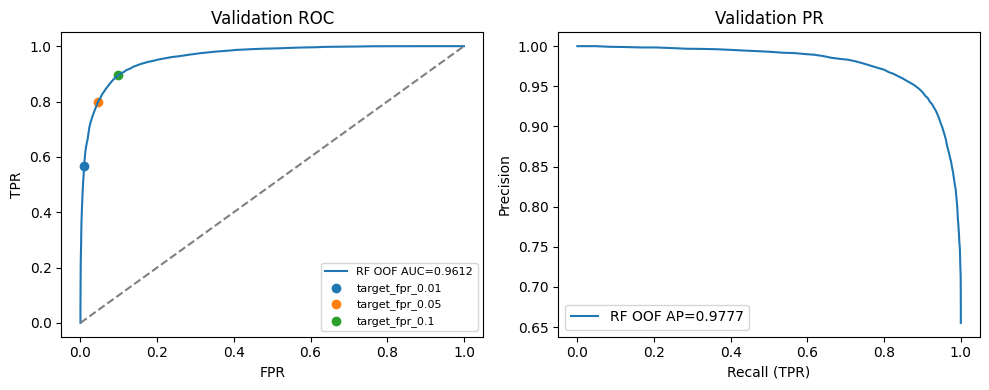

In [10]:
def choose_threshold(y, p_mon, target):
    if not 0 <= target <= 1: raise ValueError("목표 FPR은 0~1이어야 합니다.")
    fpr,tpr,thresholds = roc_curve(y,p_mon,pos_label=1,drop_intermediate=False)
    # sklearn 버전과 관계없이 '전부 Unmonitored' 선택지를 유한한 값으로 둡니다.
    thresholds[0] = np.nextafter(float(np.max(p_mon)),np.inf)
    eligible = np.flatnonzero(fpr <= target)
    best = sorted(eligible,key=lambda i:(-tpr[i],fpr[i],-thresholds[i]))[0]
    return float(thresholds[best])

THRESHOLDS = None
if "open_binary" in SELECTED:
    d, out = TASK_DATA["open_binary"], OOF["open_binary"]
    y = d["train"].y.to_numpy()
    p = out["proba"][:,list(d["classes"]).index(1)]
    threshold_rows = []
    threshold_rows.append(dict(rule="native_default",target_fpr=None,threshold=0.5,
        comparison="p_mon > 0.5",**score_metrics(y,out["pred"],"open_binary")))
    threshold_rows.append(dict(rule="threshold_0.5_ge",target_fpr=None,threshold=0.5,
        comparison="p_mon >= threshold",**score_metrics(y,np.where(p>=0.5,1,-1),"open_binary")))
    for target in FPR_TARGETS:
        threshold = choose_threshold(y,p,target)
        m = score_metrics(y,np.where(p>=threshold,1,-1),"open_binary")
        assert m["fpr"] <= target+1e-12
        threshold_rows.append(dict(rule=f"target_fpr_{target:g}",target_fpr=target,
            threshold=threshold,comparison="p_mon >= threshold",**m))
    THRESHOLDS = pd.DataFrame(threshold_rows)
    folder = RUN_DIR/"open_binary"
    atomic_csv(THRESHOLDS,folder/"experiment5_oof_thresholds.csv")
    atomic_json(folder/"frozen_thresholds.json",dict(source="selected_candidate_OOF_only",
        candidate=SELECTED["open_binary"],signature=out["signature"],
        targets_status="three predeclared analysis targets; official team target remains to be agreed; do not choose by test results",
        rules=threshold_rows,validation_mon_prevalence=float(np.mean(y==1))))
    display(THRESHOLDS.round(5))
    print(f"검증 데이터 Monitored 비율: {np.mean(y==1):.4f}; Precision은 이 비율에 영향을 받습니다.")
    fpr,tpr,t = roc_curve(y,p,pos_label=1,drop_intermediate=False)
    precision,recall,pt = precision_recall_curve(y,p,pos_label=1)
    atomic_csv(pd.DataFrame({"fpr":fpr,"tpr":tpr,"threshold":t}),folder/"roc_curve.csv")
    atomic_csv(pd.DataFrame({"precision":precision,"recall":recall,
                            "threshold":np.r_[pt,np.nan]}),folder/"pr_curve.csv")
    fig,axs = plt.subplots(1,2,figsize=(10,4))
    axs[0].plot(fpr,tpr,label=f"RF OOF AUC={roc_auc_score(y,p):.4f}")
    axs[0].plot([0,1],[0,1],"--",color="gray")
    for r in threshold_rows[2:]: axs[0].scatter(r["fpr"],r["tpr"],label=r["rule"])
    axs[0].set(xlabel="FPR",ylabel="TPR",title="Validation ROC"); axs[0].legend(fontsize=8)
    axs[1].plot(recall,precision,label=f"RF OOF AP={average_precision_score(y,p):.4f}")
    axs[1].set(xlabel="Recall (TPR)",ylabel="Precision",title="Validation PR"); axs[1].legend()
    fig.tight_layout(); fig.savefig(folder/"experiment5_validation_curves.png",dpi=160); plt.show()
else:
    print("open_binary를 TASKS에 포함해야 실험 5를 실행할 수 있습니다.")


## 7. 선택 RF 최종 학습 — 실험 4·6용 test 확률 저장

과제당 선택 모델을 **train 전체로 한 번** 학습합니다. test는 fit에 포함하지 않습니다.
확률 파일에는 `record_id, pred, p_클래스`를 저장하고 **test 정답은 넣지 않습니다.**
설정을 바꾸지 않고 재실행하면 저장한 확률도 재사용합니다.

이 RF 확률은 **확률 보정을 하지 않은 원본**입니다. 향후 soft voting 전에 LR·SVM과 ID·클래스 열을 맞추고,
동일한 검증 절차에서 확률 보정 필요성과 결합 성능을 점검해야 합니다. 보정이 필요하면 train 내부에서 수행하며 test 정답을 쓰지 않습니다.
이 파일이 생성되었다고 실험 6을 완료한 것은 아닙니다.


In [11]:
FINAL = {}
if EXPORT_TEST_PROBABILITIES or EVALUATE_FINAL_TEST:
    for task in TASKS:
        d, candidate = TASK_DATA[task], SELECTED[task]
        tr, te, classes = d["train"], d["test"], d["classes"]
        sig = joblib_hash((SCHEMA,task,tr[["record_id","y"]+FEATS],te[["record_id"]+FEATS],
                          model_for(candidate).get_params(),VERSIONS))
        folder = RUN_DIR/task
        cache = folder/f"final_{sig[:16]}.npz"
        if USE_CACHE and cache.is_file():
            with np.load(cache,allow_pickle=False) as z:
                if z["signature"].item()!=sig or not np.array_equal(z["record_id"],te.record_id.to_numpy(dtype=str)):
                    raise ValueError("최종 확률 캐시 불일치")
                pp, pred = z["proba"].copy(),z["pred"].copy()
                fit_s,predict_s = float(z["fit_s"]),float(z["predict_s"])
                importance = z["importance"].copy()
            print(f"[재사용] {task}: 최종 확률",flush=True)
        else:
            print(f"[최종 학습] {task}/{candidate['name']}",flush=True)
            state = threading.Event(); start = time.perf_counter()
            def final_report(task_name=task,event=state,started=start):
                while not event.wait(HEARTBEAT_SECONDS):
                    print(f"[진행] {task_name}: 최종 학습·예측 중, 경과 {(time.perf_counter()-started)/60:.1f}분",flush=True)
            thread = threading.Thread(target=final_report,daemon=True); thread.start()
            try:
                model = model_for(candidate)
                t = time.perf_counter(); model.fit(tr[FEATS],tr.y); fit_s = time.perf_counter()-t
                t = time.perf_counter(); pp = aligned_proba(model,te[FEATS],classes)
                pred = classes[np.argmax(pp,axis=1)]; predict_s = time.perf_counter()-t
                importance = model.feature_importances_.copy(); del model
                if USE_CACHE:
                    atomic_npz(cache,signature=np.array(sig),record_id=te.record_id.to_numpy(dtype=str),
                        classes=classes,proba=pp,pred=pred,importance=importance,
                        fit_s=np.array(fit_s),predict_s=np.array(predict_s))
            finally:
                state.set(); thread.join(timeout=1)
        FINAL[task] = dict(proba=pp,pred=pred,classes=classes,fit_s=fit_s,predict_s=predict_s)
        export_predictions(folder,"test",te,classes,pred,pp,include_y=False)
        atomic_csv(pd.DataFrame({"feature":FEATS,"importance":importance})
                   .sort_values("importance",ascending=False),folder/"selected_feature_importance.csv")
        atomic_json(folder/"final_fit.json",dict(candidate=candidate,signature=sig,
            fit_s=fit_s,predict_s=predict_s,n_train=len(tr),n_test=len(te),test_labels_used=False))
        print(f"[저장] {task}: test 확률 {pp.shape}, 지표 평가는 다음 셀 설정에 따름",flush=True)
else:
    print("최종 학습·test 확률 저장을 생략했습니다.")


[최종 학습] closed_world/trees_500
[저장] closed_world: test 확률 (3800, 95), 지표 평가는 다음 셀 설정에 따름
[최종 학습] open_multi/depth_none
[저장] open_multi: test 확률 (5800, 96), 지표 평가는 다음 셀 설정에 따름
[최종 학습] open_binary/depth_none
[저장] open_binary: test 확률 (5800, 2), 지표 평가는 다음 셀 설정에 따름


## 8. 최종 test 평가 — 팀 조건 확정 후 실행

기본은 비활성화입니다. **test 지표를 보고 후보·임계값을 다시 선택하지 않습니다.**
0번에서 `EVALUATE_FINAL_TEST=True`로 바꾸고 위에서부터 실행하면 완료 fold·확률은 캐시로 재사용합니다.
실험 5의 임계값은 6번에서 고른 값을 그대로 적용합니다.


In [12]:
TEST_SUMMARY = None
if EVALUATE_FINAL_TEST:
    rows = []
    for task in TASKS:
        d, out = TASK_DATA[task], FINAL[task]
        y, pred = d["test"].y.to_numpy(), out["pred"]
        rows.append(dict(task=task,model="RF",candidate=SELECTED[task]["name"],
            n_features=len(FEATS),n_test=len(y),fit_s=out["fit_s"],predict_s=out["predict_s"],
            **score_metrics(y,pred,task,out["proba"],out["classes"])))
        atomic_csv(d["test"][["record_id","y"]].assign(pred=pred),
                   RUN_DIR/task/"test_labeled_predictions.csv")
        if task != "open_binary":
            cm = confusion_matrix(y,pred,labels=d["classes"])
            atomic_csv(pd.DataFrame(cm,columns=[str(c) for c in d["classes"]])
                .assign(true_label=d["classes"]),RUN_DIR/task/"test_confusion_matrix.csv")
            site = pd.DataFrame({"site":y,"correct":y==pred})
            site = site.loc[site.site>=0].groupby("site").agg(n=("correct","size"),
                n_correct=("correct","sum"),accuracy=("correct","mean")).reset_index()
            atomic_csv(site,RUN_DIR/task/"test_mon_site_accuracy.csv")
    TEST_SUMMARY = pd.DataFrame(rows)
    atomic_csv(TEST_SUMMARY,RUN_DIR/"experiment4_rf_test_summary.csv")
    display(TEST_SUMMARY.round(4))
    if THRESHOLDS is not None:
        y = TASK_DATA["open_binary"]["test"].y.to_numpy()
        out = FINAL["open_binary"]
        p = out["proba"][:,list(out["classes"]).index(1)]
        rows = []
        for r in THRESHOLDS.to_dict("records"):
            pred = out["pred"] if r["rule"]=="native_default" else np.where(p>=r["threshold"],1,-1)
            rows.append(dict(rule=r["rule"],target_fpr=r["target_fpr"],threshold=r["threshold"],
                             **score_metrics(y,pred,"open_binary")))
        test_thresholds = pd.DataFrame(rows)
        atomic_csv(test_thresholds,RUN_DIR/"open_binary"/"experiment5_test_fixed_thresholds.csv")
        display(test_thresholds.round(5))
else:
    print("test 지표 미평가: 평가하려면 EVALUATE_FINAL_TEST=True로 설정하세요. CV 선택 결과는 그대로 사용합니다.")


,task,model,candidate,n_features,n_test,fit_s,predict_s,acc,macro_f1,TP,FN,TN,FP,tpr,tnr,fpr,precision,mon_site_exact,roc_auc,average_precision
0,closed_world,RF,trees_500,110,3800,154.7006,0.6627,0.8600,0.8594,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,open_multi,RF,depth_none,110,5800,48.7957,0.4070,0.8312,0.8244,3028.0,772.0,1970.0,30.0,0.7968,0.9850,0.0150,0.9902,0.7503,NaN,NaN
2,open_binary,RF,depth_none,110,5800,26.8193,0.1064,0.9031,0.8888,3659.0,141.0,1579.0,421.0,0.9629,0.7895,0.2105,0.8968,NaN,0.9676,0.982


,rule,target_fpr,threshold,acc,macro_f1,TP,FN,TN,FP,tpr,tnr,fpr,precision
0,native_default,NaN,0.50,0.90310,0.88880,3659,141,1579,421,0.96289,0.7895,0.2105,0.89681
1,threshold_0.5_ge,NaN,0.50,0.90121,0.88612,3669,131,1558,442,0.96553,0.7790,0.2210,0.89248
2,target_fpr_0.01,0.01,0.85,0.72500,0.72457,2217,1583,1988,12,0.58342,0.9940,0.0060,0.99462
3,target_fpr_0.05,0.05,0.73,0.86362,0.85772,3095,705,1914,86,0.81447,0.9570,0.0430,0.97296
4,target_fpr_0.1,0.10,0.64,0.90276,0.89492,3410,390,1826,174,0.89737,0.9130,0.0870,0.95145


## 9. 팀 공유용 파일 목록과 해석

| 파일 | 용도 |
|---|---|
| `protocol.json`, `split_used.csv` | 110개 특징·버전·분할 확인 |
| `<task>/cv_assignment.csv` | 다른 모델과 같은 검증 ID·fold를 사용할 때 기준 |
| `<task>/experiment3_candidates.csv` | 5개 후보 CV·시간·선택 여부 |
| `<task>/experiment3_paired_fold_deltas.csv` | 같은 fold의 기준 대비 차이 |
| `<task>/selected_params.json` | 고정한 최종 RF 설정 |
| `experiment4_rf_cv_summary.csv` | 세 과제의 RF 검증 결과 |
| `<task>/oof_predictions.csv`, `oof_probabilities.npz` | 검증 정답·예측·전체 클래스 확률 |
| `<task>/test_predictions.csv`, `test_probabilities.npz` | test 정답 없는 RF 확률, 실험 6 준비 |
| `<task>/probability_columns.json` | 확률 열에 대응하는 클래스·특징 순서 |
| `open_binary/experiment5_oof_thresholds.csv`, `frozen_thresholds.json` | 검증에서 선택한 임계값 |
| `experiment4_rf_test_summary.csv` | 최종 평가를 켠 경우에만 생성 |
| `open_binary/experiment5_test_fixed_thresholds.csv` | 고정 임계값 최종 평가를 켠 경우에만 생성 |

NPZ 읽기 예: `z = np.load(path, allow_pickle=False)` → `z['record_id']`, `z['classes']`, `z['proba']`.
확률 행은 ID로 정렬·결합하고 열은 classes로 맞춰야 합니다. CSV에도 동일한 정보가 있습니다.

**해석 범위**

- 5개 후보는 한 항목씩 점검하는 소규모 검증입니다. 모든 조합의 최적값이나 튜닝 충분성을 증명하지 않습니다.
- None이 더 좋다면 이전 제한 깊이가 성능을 낮췄을 가능성을 볼 수 있습니다. 다른 조건이 같은 비교에서만 해석하세요.
- 트리 500개의 미세한 이득은 추가 시간과 함께 판단합니다. 측정 시간은 실행 환경에 따라 달라집니다.
- 학습 정확도와 CV 차이는 참고 지표이며, 그 값 하나로 과적합·일반화 성능을 단정하지 않습니다.
- 같은 CV로 후보·임계값을 선택해 CV 성능은 낙관적일 수 있습니다. 별도 test는 최종 확인용입니다.
- fold 간 자료가 독립적이지 않으므로 표준편차의 배수만으로 통계적 유의성을 주장하지 않습니다.
- RF도 확률이 자동으로 잘 보정되었다고 가정하지 않습니다. 현재 원본 확률은 실험 6의 입력 준비입니다.
- Closed-world와 Open-world 다중을 주요 결과로, 이진을 보조 결과 및 탐지 임계값 분석으로 보고합니다.
- 110개 특징 유지 조건의 결과입니다. 100지점 특징 개선 결과와 섞어 모델 우열을 해석하지 않습니다.

실험 6을 완료하려면 LR·SVM의 같은 조건 OOF/test 확률, 클래스 순서, 확률 보정·결합 규칙이 추가로 필요합니다.
세 모델 모두 다시 학습하는 앙상블 코드는 이 RF 담당용 노트북에 포함하지 않았습니다.

참고: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[임계값 조정](https://scikit-learn.org/stable/modules/classification_threshold.html),
[Soft voting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html).


In [13]:
print("완료. 결과 폴더:", RUN_DIR)
print("팀에 먼저 공유할 것: protocol.json, split_used.csv, 과제별 cv_assignment.csv / selected_params.json")
print("확률 파일: 과제별 oof_predictions.csv / test_predictions.csv, probability_columns.json")
print("이 노트북은 RF만 수행했습니다. LR·SVM 비교 및 soft voting은 별도 작업입니다.")


완료. 결과 폴더: /content/drive/MyDrive/MLB-Project/results/rf_experiments3_4_5_110features/runs/29c10470afbc6158f597ca2749dac781
팀에 먼저 공유할 것: protocol.json, split_used.csv, 과제별 cv_assignment.csv / selected_params.json
확률 파일: 과제별 oof_predictions.csv / test_predictions.csv, probability_columns.json
이 노트북은 RF만 수행했습니다. LR·SVM 비교 및 soft voting은 별도 작업입니다.
